# 05 · Planned contrasts and sensitivity to category × week shocks

The planned contrasts test whether the association between discount and sales varies by store segment, brand type (manufacturer brand or private label) or category. The Holm correction covers this fixed family of three tests. The residual diagnostic in notebook 03 motivates the second analysis, which compares F3 with a version that adds a category × week random intercept.

The scripts `scripts/fit_contrasts.py` and `scripts/fit_catweek_sensitivity.py` fitted the models on the 104 training weeks (0 to 103) and stored the results in `outputs/runs`. Both language versions read the same runs. The estimates describe conditional associations in weeks with recorded transactions. The selection of C0 and the P1 model ranking are based on out-of-sample prediction error, documented in notebook 04.

*Data: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "en"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import viz
from retail_multilevel.i18n import contrast_label, format_p, level_label, localize_columns, t
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
contrasts = load_run("p2_contrasts", "20261124-220904-eb35f45e")
catweek = load_run("p2_catweek", "20261124-220500-f7c26a70")
print(t("data_credit", LANG))
stored = {"contrasts": contrasts, "catweek": catweek}
display(pd.DataFrame({k: {"run_id": r.run_id, "finished_at": r.metadata["finished_at"]} for k, r in stored.items()}).T)

MODELS = {"F3_ref": t("model_f3_ref", LANG), "F3_catweek": t("model_f3_catweek", LANG)}
GROUPS = {"CATWEEK": t("group_catweek", LANG)}


def localized(df):
    out = df.copy()
    if "test" in out:
        for col in ("level", "reference"):
            if col in out:
                out[col] = [level_label(a, b, LANG) for a, b in zip(out["test"], out[col], strict=True)]
        out["test"] = [contrast_label(x, LANG) for x in out["test"]]
    if "model" in out:
        out["model"] = out["model"].map(lambda x: MODELS.get(x, x))
    if "group" in out:
        out["group"] = out["group"].map(lambda x: GROUPS.get(x, viz.group_label(x, LANG)))
    if "term" in out:
        out["term"] = [viz.term_label(x, LANG) for x in out["term"]]
    return localize_columns(out, LANG)

Data: dunnhumby Source Files – Breakfast at the Frat


,run_id,finished_at
contrasts,20261124-220904-eb35f45e,2026-11-24T22:09:20.929617
catweek,20261124-220500-f7c26a70,2026-11-24T22:09:34.923902


The two runs that were read are identified above (identifier and finish time). The identifiers are fixed in the code, so re-running the notebook always reads the same artefacts.

## 1. The question and the design of the contrasts

The question is whether the slope of log(units) on the log of the discount (`LOG_DISC`) is the same at every level of a moderator. The moderators are the store segment (reference `MAINSTREAM`), the brand type (reference: manufacturer brand) and the category (reference `BAG SNACKS`, the first in alphabetical order). One model was fitted for each moderator, by least squares with store × product pair and week fixed effects, obtained through the within transformation (Wooldridge, 2010). The response is `LOG_UNITS`, and the controls are `LOG_DISC`, `LOG_BASE_PRICE`, `FEATURE`, `DISPLAY` and `TPR_ONLY`, the same as in the within-pair sensitivity of notebook 03. The model with interaction adds `LOG_DISC` multiplied by the indicator of each level other than the reference, and the restricted version, with the same sample and the same controls, omits those interactions.

Pair fixed effects absorb the main effects of segment, brand type and category because each attribute is constant within a pair. Discounts vary across weeks within a pair. That variation identifies the interaction with `LOG_DISC` by comparing the within-pair relationship between sales and discounts across levels.

The contrasts compare slopes across groups defined by the moderators. In protocol P1 (notebook 04), candidate C1 allows discount elasticity to vary randomly across stores and products (Gelman & Hill, 2007). P1 evaluates that candidate using out-of-sample prediction error.

## 2. Populations and support by level

The first operational question is which rows enter each test. The table below shows, for each moderator, the training rows, the rows used, the pairs and the exclusions.

In [3]:
display(localized(contrasts.load_table("populations")))

,Test,Training rows,Rows,Pairs,Excluded rows,Exclusion reason
0,Segment,347092,338033,3763,9059,SEG_AMBIGUOUS=9059; missing SEGMENT=0
1,Brand type,347092,347092,3859,0,missing PRIVATE_LABEL=0
2,Category,347092,347092,3859,0,missing CATEGORY=0


The segment test uses 338,033 rows and 3,763 pairs, after the exclusion of 9,059 rows from the two stores with an ambiguous segment (4503 and 17627); no segment is missing. The brand-type and category tests use the 347,092 rows and the 3,859 pairs of the training sample, with no unclassified cases. The reference of each factor was fixed before the estimates were inspected.

The second question is whether there is discount variation within the pair at each level, because that variation is what identifies the interaction. The next table shows, by level, the rows, the pairs, the within-pair standard deviation of `LOG_DISC` and the number of pairs with discount variation.

In [4]:
display(localized(contrasts.load_table("support")))

,Test,Level,Rows,Pairs,Within-pair SD of LOG_DISC,Pairs with discount variation
0,Segment,MAINSTREAM,190805,2078,0.1369,2058
1,Segment,UPSCALE,70965,764,0.1303,761
2,Segment,VALUE,76263,921,0.1391,887
3,Brand type,National brand,255828,2937,0.1296,2881
4,Brand type,Private label,91264,922,0.1520,921
5,Category,BAG SNACKS,84270,889,0.1010,873
6,Category,COLD CEREAL,114480,1155,0.1281,1155
7,Category,FROZEN PIZZA,71242,827,0.1359,816
8,Category,ORAL HYGIENE PRODUCTS,77100,988,0.1749,958


Every level has discount variation within the pair. The share of pairs with `LOG_DISC` variation ranges from 96.3% (VALUE, with 887 of 921 pairs) to 100% (COLD CEREAL, with 1,155 of 1,155 pairs), and the within-pair standard deviation of the discount ranges from 0.101 (BAG SNACKS) to 0.175 (ORAL HYGIENE PRODUCTS). There is, therefore, variation from which to extract each slope, although the distribution of discounts differs across levels.

## 3. The global tests and the Holm correction

For each moderator, the joint null hypothesis is that all slope differences relative to the reference are zero. The statistic is a joint Wald test of the q interactions, computed with the full covariance matrix clustered two ways, by pair and by week (Cameron et al., 2011). Because there are 104 weeks, fewer than the number of pairs, the reference is an F(q, 103), that is, with `min(G_pair, G_week) − 1` denominator degrees of freedom, an approximate convention for the number of clusters in the smaller dimension (Cameron & Miller, 2015). The F statistic is the Wald statistic divided by q. The table shows the statistic, the number of restrictions, the degrees of freedom, the cluster counts and the raw p-value.

In [5]:
wald = contrasts.load_table("wald")
tests = wald[["test", "reference", "q", "W", "F", "df1", "df2", "G_pair", "G_week"]].assign(
    p_raw=[format_p(p) for p in wald["p_raw"]]
)
display(localized(tests))

,Test,Reference,Restrictions (q),Wald statistic,F = W / q,Numerator df,Denominator df,Pair clusters,Week clusters,Raw p-value
0,Segment,MAINSTREAM,2,12.2484,6.1242,2,103,3763,104,0.0031
1,Brand type,National brand,1,30.2717,30.2717,1,103,3859,104,2.76e-07
2,Category,BAG SNACKS,3,111.0092,37.0031,3,103,3859,104,2.61e-16


The segment test (q = 2) has F = 6.12 and a raw p-value of 0.0031; the brand-type test (q = 1), F = 30.27 and a p-value of 2.76e-07; the category test (q = 3), F = 37.00 and a p-value of 2.61e-16. The reliability of these values depends on diagnostics of the design and of the covariance, presented next: the rank of the design matrix, the condition number of the q × q block of the covariance of the interactions and its smallest eigenvalue, and the indication of whether a correction for positive semidefiniteness was needed.

In [6]:
diagnostics = wald[
    ["test", "design_rank", "n_terms", "rank_deficient", "cond_number", "min_eig", "twoway_psd_fixed", "design_cond", "available"]
]
display(localized(diagnostics))

,Test,Design rank,Design columns,Rank deficient,Condition number of the q × q block,Smallest eigenvalue of the block,PSD correction applied,Design condition number,Available
0,Segment,7,7,False,2.1801,0.0017,False,12.5665,True
1,Brand type,6,6,False,1.0000,0.0081,False,13.0660,True
2,Category,8,8,False,5.9744,0.0043,False,46.0431,True


The three designs have full rank (7, 6 and 8 columns), none needed a correction for positive semidefiniteness, and the q × q block of the covariance has a condition number of at most 6.0, with a smallest eigenvalue between 0.0017 and 0.0081. The three tests are therefore available.

The Holm correction is applied to a fixed family of three global tests, at the 5% level (Holm, 1979). The raw p-values, in ascending order, are multiplied by 3, 2 and 1, with monotonicity enforced. If a test were unavailable, because of lost rank or an unstable covariance, the family would keep three positions, and the p-value of the unavailable position would enter as 1 in the adjustment and be displayed as unavailable. Here, no position is unavailable.

In [7]:
holm = contrasts.load_table("holm")
holm_view = holm.assign(
    p_raw=[format_p(p) for p in holm["p_raw"]],
    p_holm=[format_p(p) if ok else t("p_unavailable", LANG) for p, ok in zip(holm["p_holm"], holm["available"], strict=True)],
)
display(localized(holm_view))

,Test,Raw p-value,Holm-adjusted p-value,Rejects at 5%,Available
0,Segment,0.0031,0.0031,True,True
1,Brand type,2.76e-07,5.51e-07,True,True
2,Category,2.61e-16,7.83e-16,True,True


After the adjustment, the p-values are 0.0031 for segment, 5.51e-07 for brand type and 7.83e-16 for category, and the three tests reject the global null hypothesis at 5%. The adjustment changes the decision of none of the three tests, and the segment test, the one with the weakest evidence in the family, keeps its raw p-value because it occupies the last position of the ordering.

Two cautions accompany this reading. The first is that two-way clustering accommodates dependence within the pair, such as serial correlation between weeks of the same pair, and contemporaneous shocks shared among pairs in the same week. Dependence outside those dimensions, in particular persistent common shocks across weeks, is not covered, so the test is treated as approximate. The second is that the two-way covariance is much larger than the one clustered by pair only, as the table below shows for the `LOG_DISC` coefficient in the restricted model: the two-way standard error, about 0.079, is about 1.8 times the pair-clustered one, about 0.044, so an inference based only on pair clustering would be optimistic.

In [8]:
coef = contrasts.load_table("coefficients")
restricted = coef[(coef["model"] == "restricted") & (coef["term"] == "LOG_DISC")]
display(localized(restricted.drop(columns=["model", "term"]).rename(columns={"estimate": "slope"})))

,Test,Slope,SE by pair,SE by week,SE two-way
0,Segment,-1.7017,0.0445,0.0732,0.0793
12,Brand type,-1.7031,0.0437,0.0729,0.0788
23,Category,-1.7031,0.0437,0.0729,0.0788


## 4. Slopes by level

A more negative slope indicates that the same discount change is associated with a larger change in units sold. For each level, the table reports the estimated slope, its standard errors, the difference from the reference and the corresponding 95% intervals. The intervals are pointwise, calculated using the two-way standard error, with no multiplicity adjustment. Differences by level are descriptive. Inference is limited to the planned family of three global tests.

,Test,Level,Reference level,Slope,SE by pair,SE by week,SE two-way,Lower 95% (pointwise),Upper 95% (pointwise),Difference vs. reference,SE of difference,"Difference, lower 95%","Difference, upper 95%"
0,Segment,MAINSTREAM,True,-1.7458,0.0541,0.0779,0.0856,-1.9155,-1.5761,0.0000,0.0000,0.0000,0.0000
1,Segment,UPSCALE,False,-1.5795,0.0453,0.0678,0.0766,-1.7315,-1.4276,0.1663,0.0475,0.0720,0.2606
2,Segment,VALUE,False,-1.6857,0.0561,0.0745,0.0886,-1.8613,-1.5100,0.0601,0.0565,-0.0518,0.1721
3,Brand type,National brand,True,-1.9058,0.0440,0.0818,0.0899,-2.0840,-1.7276,0.0000,0.0000,0.0000,0.0000
4,Brand type,Private label,False,-1.4114,0.0515,0.0824,0.0868,-1.5836,-1.2392,0.4945,0.0899,0.3162,0.6727
5,Category,BAG SNACKS,True,-1.0827,0.0627,0.0730,0.0876,-1.2563,-0.9090,0.0000,0.0000,0.0000,0.0000
6,Category,COLD CEREAL,False,-2.0441,0.0558,0.1260,0.1327,-2.3073,-1.7808,-0.9614,0.1277,-1.2147,-0.7081
7,Category,FROZEN PIZZA,False,-2.4160,0.1143,0.1509,0.1551,-2.7237,-2.1084,-1.3334,0.1360,-1.6031,-1.0637
8,Category,ORAL HYGIENE PRODUCTS,False,-1.3873,0.0355,0.0552,0.0602,-1.5067,-1.2679,-0.3046,0.0771,-0.4575,-0.1517


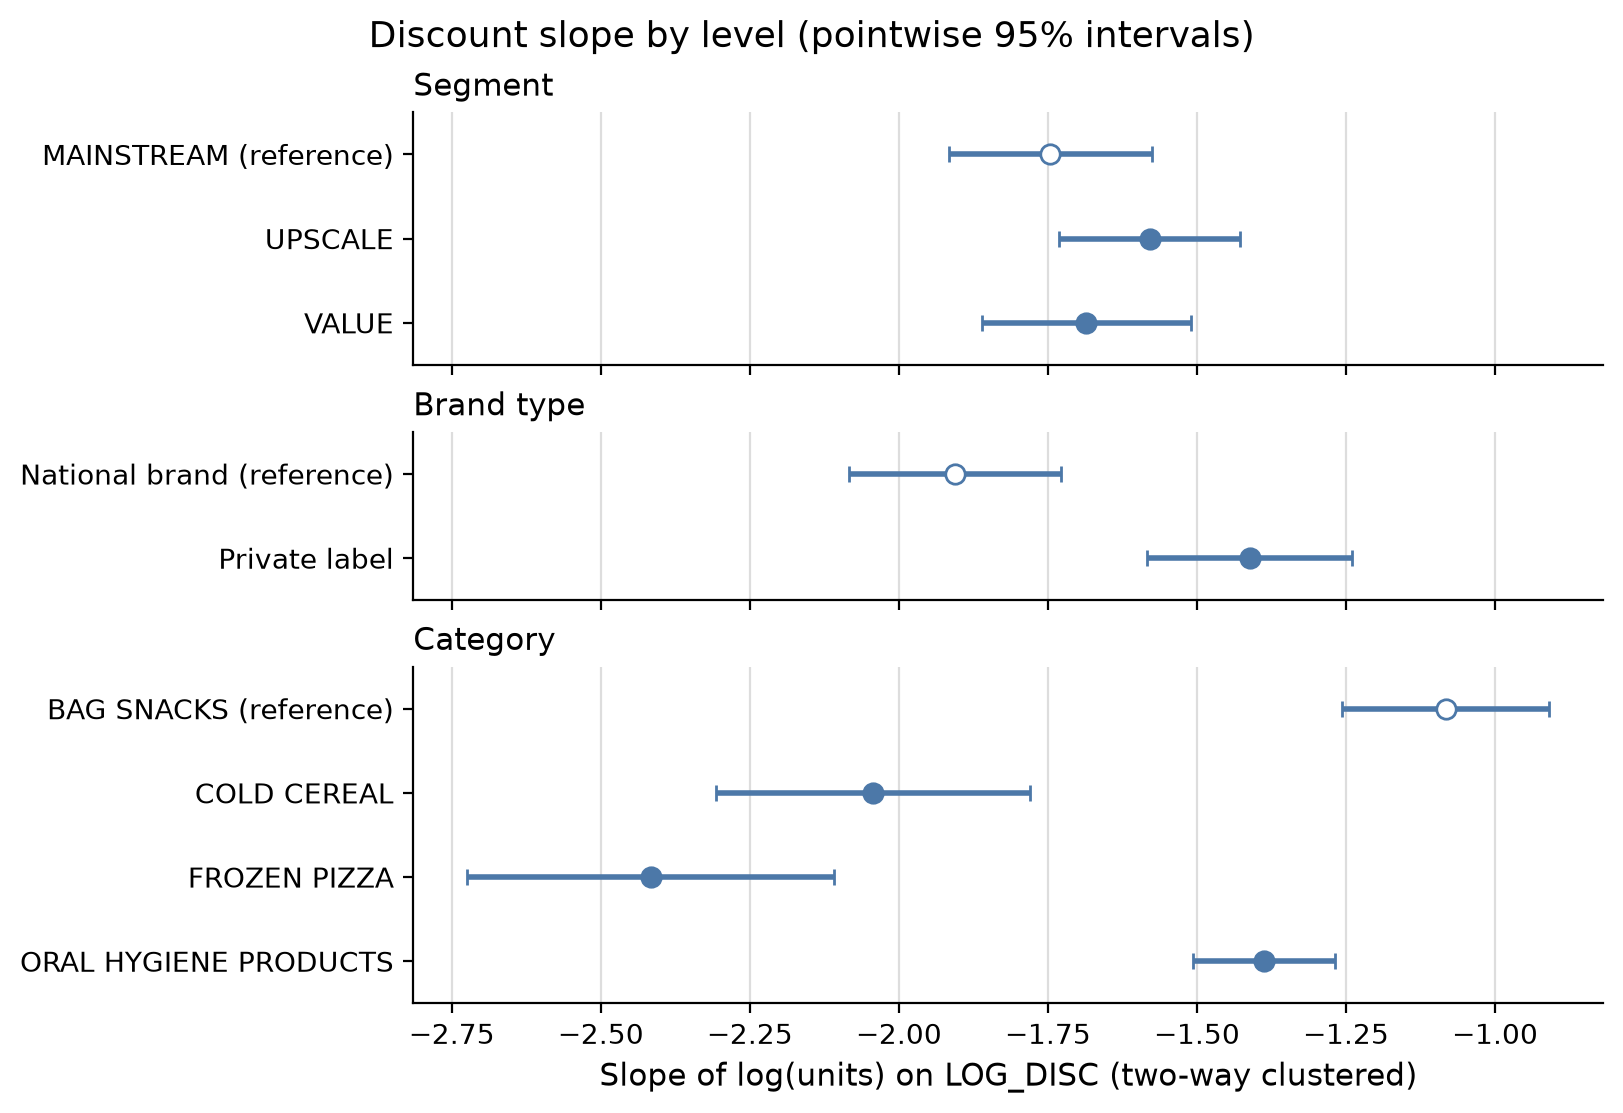

In [9]:
slopes = contrasts.load_table("slopes")
display(localized(slopes.drop(columns=["interval"])))
fig = viz.plot_moderator_slopes(slopes, LANG)

By segment, the slopes are −1.746 (MAINSTREAM, the reference), −1.580 (UPSCALE) and −1.686 (VALUE). The UPSCALE difference from the reference is 0.166, with a pointwise interval from 0.072 to 0.261, and the VALUE difference is 0.060, with an interval from −0.052 to 0.172, which contains zero. Among the level differences of the segment, only that of UPSCALE has a pointwise interval that excludes zero. This reading is descriptive, because the interval is pointwise and has no multiplicity adjustment. The global segment test indicates heterogeneity across the set of segments and does not, by itself, identify which segment differs.

By brand type, the slope is −1.906 for manufacturer brand and −1.411 for private label, a difference of 0.494 (interval from 0.316 to 0.673): the association of the discount with units is less intense for the private label. By category, the slopes are −1.083 (BAG SNACKS, the reference), −2.044 (COLD CEREAL), −2.416 (FROZEN PIZZA) and −1.387 (ORAL HYGIENE PRODUCTS), with differences from the reference of −0.961 (interval from −1.215 to −0.708), −1.333 (from −1.603 to −1.064) and −0.305 (from −0.458 to −0.152). The discount is associated with a larger response in frozen pizza and in cereal than in pretzels.

Conditional differences across levels may reflect factors outside the model, such as the distribution of discounts and the promotional calendar. Section 2 showed that the within-pair standard deviation of the discount varies across levels. The common `LOG_DISC` slope in restricted within-pair OLS is about −1.70, with pair and week fixed effects and log base price as a control. The scenarios in notebook 06 use the slope from F3 (−1.685). F3 uses random intercepts, splits base price into the pair deviation and mean, and includes trend and seasonality. The values are close and come from different estimators and controls.

## 5. Sensitivity to common category × week shocks

The residual diagnostic of notebook 03 showed that the weekly means of the conditional residuals of the F3 vary much more than expected under independence between rows, and that the share of the residual variance associated with the combination of category and week is 6.4%, against 0.1% expected. The question is whether the associations estimated by the F3 are sensitive to the representation of these common shocks. The comparison is therefore a sensitivity analysis motivated by the diagnostic of notebook 03, not a replacement of the official specification.

The reference is the F3 of notebook 03, the C0 of P1, with the fixed part of decisions D12 to D14 and random intercepts for store, product and pair, fitted by REML with `lme4` (Bates et al., 2015). The sensitivity adds `(1 | CATEGORY:WEEK)`, on the same rows, with the same fixed part and the same means learned on the training sample. A category × week intercept represents contemporaneous deviations, common to all stores and products of a category in the same week. The category × week effects are conditional on the cells already observed in training, and do not project onto future weeks. The tables below show the counts and the convergence of the two fits.

In [10]:
display(localized(catweek.load_table("counts")).T)
display(localized(catweek.load_table("convergence")))

,0
Rows,347092
Pairs,3859
Stores,77
Products,55
Categories,4
Category × week levels,416
Weeks,104
Last week,103
Rows without category,0


,Model,Optimizer,Convergence messages,Singular fit,Seconds,Parameters,Observations,REML log-likelihood,Used in the comparison
0,F3 (reference),bobyqa,,False,69.8190,18,347092,"-274,596.6559",True
1,F3 + category × week,bobyqa,,False,180.4954,19,347092,"-264,270.2786",True


The two fits use exactly the same 347,092 rows, with 3,859 pairs, 77 stores, 55 products, 4 categories and 416 category × week levels (4 categories over 104 weeks), with no missing category. Both converged with the `bobyqa` optimizer, with no convergence messages, and neither is singular, so there is no limitation to record and the comparison can be read directly. The next table compares the fixed effects.

,Term,"Estimate, F3","SE, F3","Estimate, with category × week","SE, with category × week",Difference,SE ratio
0,Discount depth (log price / base),-1.6852,0.0107,-1.7271,0.0109,-0.0419,1.0177
1,"Regular price, within pair (log)",-1.5921,0.0119,-1.6600,0.0121,-0.0679,1.0191
2,"Regular price, pair mean (log)",-0.8797,0.1054,-0.8840,0.1055,-0.0043,1.0014
3,Feature (flyer),0.4972,0.0043,0.5009,0.0044,0.0036,1.0274
4,In-store display,0.4087,0.0036,0.4020,0.0035,-0.0067,0.9806
5,Temporary price reduction (TPR),-0.0412,0.0037,-0.0366,0.0037,0.0046,0.9961
6,Trend (per year),-0.0214,0.0018,-0.0249,0.0129,-0.0035,7.3476


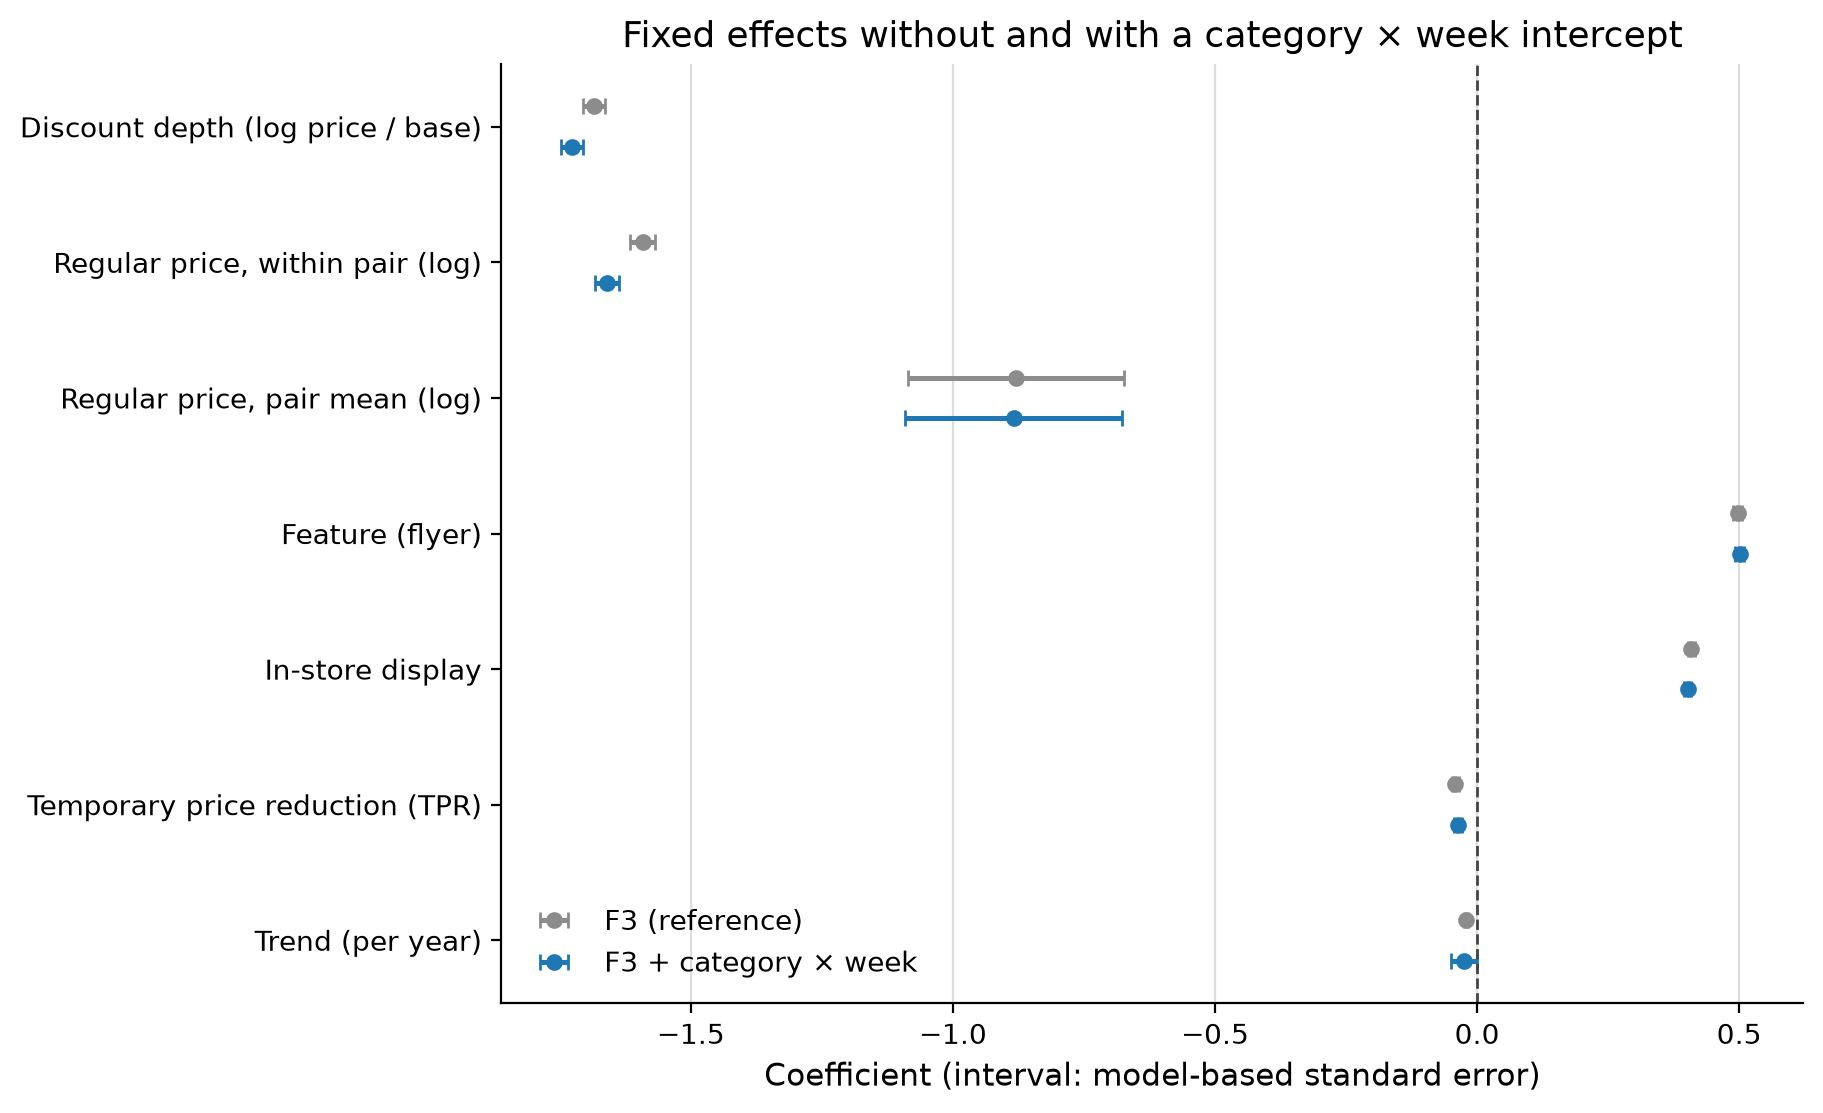

In [11]:
fixef_compare = catweek.load_table("fixef_compare")
display(localized(fixef_compare))
fig = viz.plot_catweek_compare(fixef_compare, LANG)

The discount coefficient moves from −1.685 to −1.727, and that of the regular price within the pair (`LOG_BASE_DEV`), from −1.592 to −1.660. The feature, display and TPR coefficients change by less than 0.007. The sign and the order of magnitude of all associations are kept, and the changes in discount and regular price are 2.5% and 4.3% of the reference value. There is one exception in precision: the standard error of the trend (`TREND`) is 7.3 times larger, going from 0.0018 to 0.0129, while the others stay between 0.98 and 1.03 times those of the reference. Because the trend is a function of the week only, it is largely represented by the category × week levels, and stops being well identified when they enter the model. The standard errors in this table are the model-based ones, which notebook 03 showed to be too narrow for full inference.

The next table shows the estimated variances of the two fits.

In [12]:
display(localized(catweek.load_table("varcomp")))

,Model,Grouping,Variance,Standard deviation,Share
0,F3 (reference),Store × product,0.1490,0.3861,0.1174
1,F3 (reference),Store,0.1665,0.4081,0.1312
2,F3 (reference),Product,0.6815,0.8255,0.5369
3,F3 (reference),Residual,0.2724,0.5219,0.2146
4,F3 + category × week,Store × product,0.1500,0.3873,0.1182
5,F3 + category × week,Category × week,0.0179,0.1338,0.0141
6,F3 + category × week,Store,0.1674,0.4091,0.1319
7,F3 + category × week,Product,0.6789,0.8240,0.5348
8,F3 + category × week,Residual,0.2552,0.5052,0.2011


The category × week variance is 0.0179 (standard deviation 0.134), which corresponds to 1.4% of the total variance, and the residual variance falls from 0.272 to 0.255. The store, product and pair variances barely change. The next table summarises the common shocks in the conditional residuals: the variance of the weekly means, the variance expected under independence, the ratio between them and the share of the category × week variance.

In [13]:
week_summary = catweek.load_table("week_summary")
columns = [
    "model", "var_week_means", "var_expected_independent", "variance_ratio",
    "autocorr_week_means", "share_category_week", "share_category_week_expected",
]  # fmt: skip
with pd.option_context("display.float_format", "{:,.4g}".format):
    display(localized(week_summary[columns]))

,Model,Variance of weekly mean residuals,Expected if independent,Ratio to independence,Lag-1 autocorrelation of weekly means,"Share of variance, category × week","Expected share, category × week"
0,F3 (reference),0.007861,8.088e-05,97.19,-0.004669,0.06363,0.001196
1,F3 + category × week,2.303e-06,7.57e-05,0.03042,0.01947,2.146e-05,0.001196


The ratio of the variance of the weekly means to the one expected under independence falls from 97.2 in the reference to 0.03 with the category × week intercept, and the category × week share of the residuals falls from 6.4% to 0.002%. This result is partly mechanical, because the conditional residuals are computed after subtracting the predicted category × week effects: it shows that the term absorbs the contemporaneous common shocks, not that the dependence has vanished. The lag-1 autocorrelation of the weekly means of the residuals was already close to zero in the reference (−0.005), so there is no sign of strong persistence in the aggregate weekly shocks.

Persistence within the pair is a different matter. The following table and chart compare the correlations of the conditional residuals of the same pair at calendar lags of 1 to 4 weeks.

model,F3 (reference),F3 + category × week
Lag (weeks),,
1,0.1958,0.1940
2,0.1173,0.1249
3,0.0922,0.1004
4,0.0960,0.0948


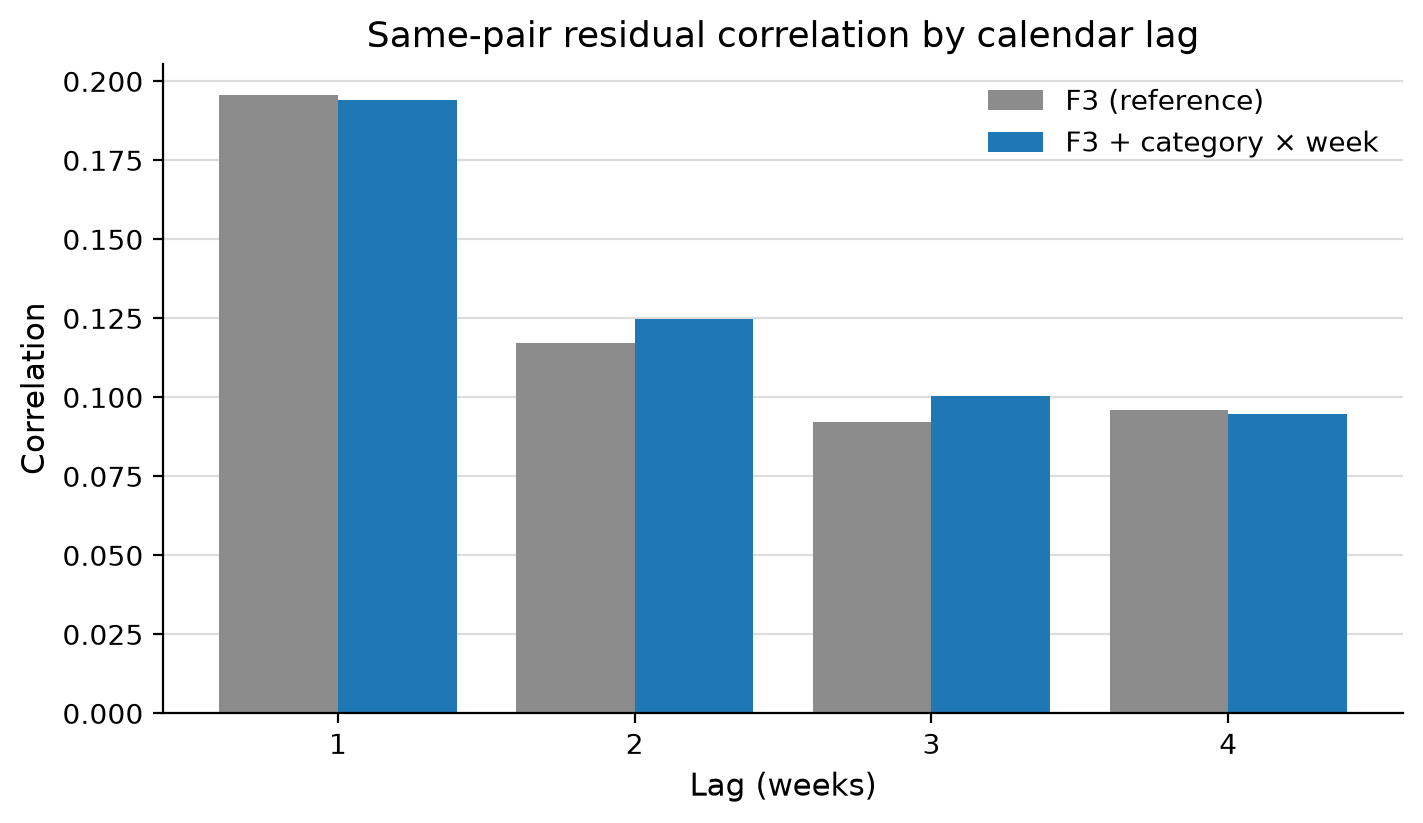

In [14]:
lag_corr = catweek.load_table("lag_corr")
wide = lag_corr.pivot(index="lag", columns="model", values="corr")[list(MODELS)].rename(columns=MODELS)
display(wide.rename_axis(t("f_lag", LANG)))
fig = viz.plot_lag_corr_compare(lag_corr, LANG)

The correlations change little: at lag 1, from 0.196 to 0.194, and at lags 2 to 4 by at most 0.008. The residual persistence within the pair is not a contemporaneous shock common to a category, so the category × week term does not represent it. In the tests of section 3, this persistence is accommodated by the pair clustering, which allows arbitrary correlation between the weeks of the same pair.

It remains to record the likelihood-ratio statistic between the two REML fits, which have the same fixed part. Because a single variance is added, the p-value comes from the 50:50 mixture of χ² with 0 and with 1 degree of freedom (Self & Liang, 1987). The p-value is not representable in floating point and is displayed as less than 1e-300, not as zero. Given the remaining dependence, this statistic is only descriptive, and no conclusion of this notebook rests on it.

In [15]:
lr = catweek.load_json("key_numbers")["lr_descriptive"]
display(
    localize_columns(
        pd.DataFrame([{"stat": lr["stat"], "df": lr["df"], "p_value": format_p(lr["p_value"])}]),
        LANG,
    )
)

,LR statistic,Degrees of freedom,"p-value (50:50 mixture, descriptive)"
0,"20,652.7545",1,< 1e-300


## 6. What the evidence allows one to conclude

After the Holm correction for the fixed family of three tests, each global test rejects equal slopes across the levels of its moderator at the 5% level. Adjusted p-values are 0.0031 for segment, 5.51e-07 for brand type and 7.83e-16 for category. The segment test has the weakest evidence of the three. Differences by level describe conditional associations with pointwise intervals. Global inference is approximate because two-way clustering can miss dependence between different pairs in different weeks, such as common shocks that persist across weeks.

Adding the category × week random intercept moves the discount coefficient from −1.685 to −1.727 and the within-pair regular price coefficient from −1.592 to −1.660. The promotion coefficients change by less than 0.007. The sign and order of magnitude of the F3 associations hold in this sensitivity analysis. Only the trend loses precision. The intercept absorbs common shocks in the same week, and within-pair residual persistence remains.

In within-pair OLS, the estimated category slopes range from −1.083 to −2.416. The scenarios in notebook 06 use the common F3 slope (−1.685) to summarise associations that vary across categories.

## References

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372. https://doi.org/10.3368/jhr.50.2.317

Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). Robust inference with multiway clustering. *Journal of Business & Economic Statistics, 29*(2), 238–249. https://doi.org/10.1198/jbes.2010.07136

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70. (partial verification: source not accessible for automated checking)

Self, S. G., & Liang, K.-Y. (1987). Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions. *Journal of the American Statistical Association, 82*(398), 605–610. https://doi.org/10.1080/01621459.1987.10478472

Wooldridge, J. M. (2010). *Econometric analysis of cross section and panel data* (2nd ed.). MIT Press. (partial verification: edition year not checked against a primary source)